# Módulo 2 — Segmentación y Morfología Matemática de la Pupila
**PupilTrack — PSIB, ITBA (2do Q 2026)**

Métodos pedidos por la guía: Otsu, K-Means, Snakes (contornos activos) y Watershed.

In [1]:
VIDEO_PATH = ""
ROI_MANUAL = None
FRAME_INDICE = None

## Setup

In [2]:
import sys, os
sys.path.append(os.path.abspath(".."))

import cv2
import numpy as np
import matplotlib.pyplot as plt

from pupiltrack import acquisition as acq
from pupiltrack import segmentation as seg
from pupiltrack import morphology as morf

plt.rcParams["figure.figsize"] = (5, 5)

def mostrar(img, titulo="", cmap="gray"):
    plt.figure(); plt.imshow(img, cmap=cmap); plt.title(titulo); plt.axis("off"); plt.show()

## Carga del frame de trabajo

Usando imagen sintética con máscara de referencia conocida.


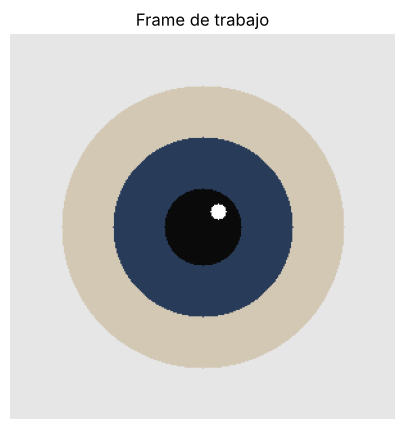

In [3]:
def generar_ojo_sintetico(size=300):
    img = np.full((size, size, 3), 230, dtype=np.uint8)
    centro = (size // 2, size // 2)
    cv2.circle(img, centro, 110, (180, 200, 210), -1)
    cv2.circle(img, centro, 70, (90, 60, 40), -1)
    cv2.circle(img, centro, 30, (10, 10, 10), -1)
    cv2.circle(img, (centro[0] + 12, centro[1] - 12), 6, (255, 255, 255), -1)
    return img

def mascara_real_sintetica(size=300, radio_pupila=30):
    m = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(m, (size // 2, size // 2), radio_pupila, 255, -1)
    return m

REFERENCIA = None

if VIDEO_PATH and os.path.exists(VIDEO_PATH):
    frames, fps = acq.extraer_frames(VIDEO_PATH)
    frame_completo = acq.frame_representativo(frames, FRAME_INDICE)
    if ROI_MANUAL is not None:
        x, y, w, h = ROI_MANUAL
        frame = frame_completo[y:y+h, x:x+w]
    else:
        frame, roi = acq.seleccionar_roi(frame_completo)
        print("ROI seleccionada:", roi)
else:
    frame = generar_ojo_sintetico()
    REFERENCIA = mascara_real_sintetica()
    print("Usando imagen sintética con máscara de referencia conocida.")

gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
mostrar(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB), "Frame de trabajo")

## 2.1 — Algoritmos de segmentación

**Umbralización global (Otsu, Li, Triangle):**

Umbrales -> Otsu: 57.0 | Li: 111.6 | Triangle: 229.0


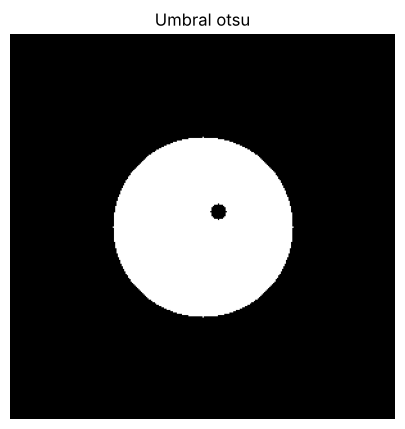

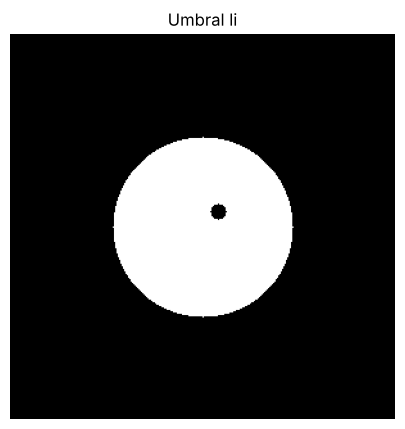

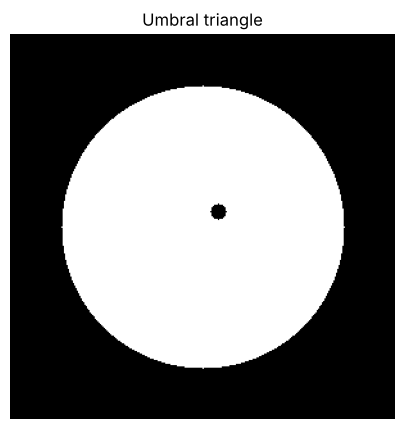

In [4]:
m_otsu, t_otsu = seg.umbral_otsu(gris)
m_li, t_li = seg.umbral_li(gris)
m_tri, t_tri = seg.umbral_triangle(gris)
print(f"Umbrales -> Otsu: {t_otsu:.1f} | Li: {t_li:.1f} | Triangle: {t_tri:.1f}")

mascaras = {
    "otsu": cv2.bitwise_not(m_otsu),
    "li": cv2.bitwise_not(m_li),
    "triangle": cv2.bitwise_not(m_tri),
}
for nombre, m in mascaras.items():
    mostrar(m, f"Umbral {nombre}")

**K-Means (K=2 a 5, agrupamiento por intensidad):**

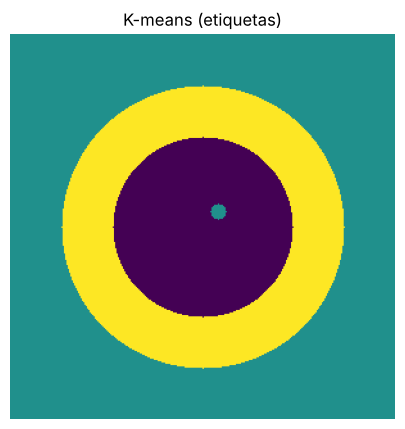

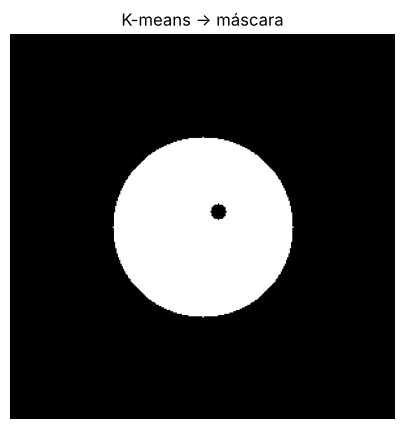

In [5]:
etiquetas, centros = seg.segmentar_kmeans(gris, k=3)
mascaras["kmeans"] = seg.mascara_desde_kmeans(etiquetas, centros, cluster_mas_oscuro=True)
mostrar(etiquetas, "K-means (etiquetas)", cmap="viridis")
mostrar(mascaras["kmeans"], "K-means -> máscara")

**Contornos Activos (Snakes):**

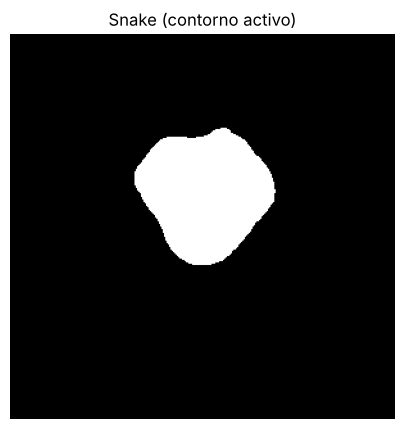

In [6]:
mascara_snake = seg.segmentar_snake(gris)
mascaras["snake"] = mascara_snake
mostrar(mascara_snake, "Snake (contorno activo)")

**Watershed (cuenca hidrográfica, por transformada de distancia):**

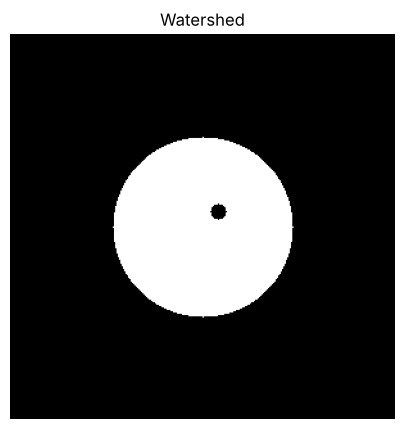

In [7]:
mascara_ws = seg.segmentar_watershed(gris)
mascaras["watershed"] = mascara_ws
mostrar(mascara_ws, "Watershed")

**Region Growing** (referencia adicional, útil cuando iris+pupila tienen intensidad similar):

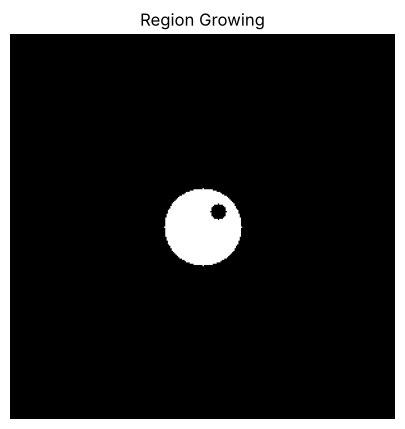

In [8]:
semilla = seg.elegir_semilla_automatica(gris, modo="minimo")
mascaras["region_growing"] = seg.region_growing(gris, semilla, tolerancia=15)
mostrar(mascaras["region_growing"], "Region Growing")

## 2.2 — Morfología matemática para limpieza de máscara

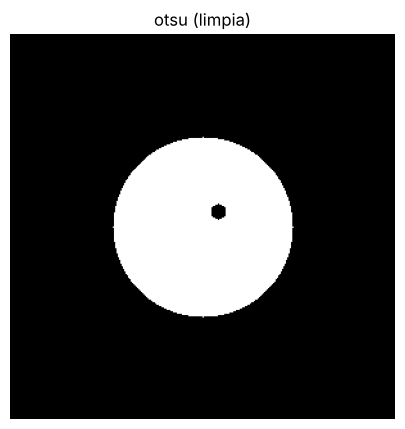

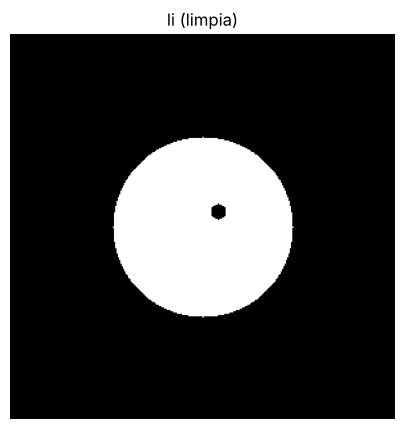

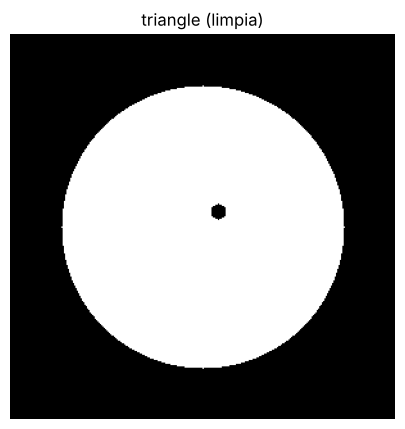

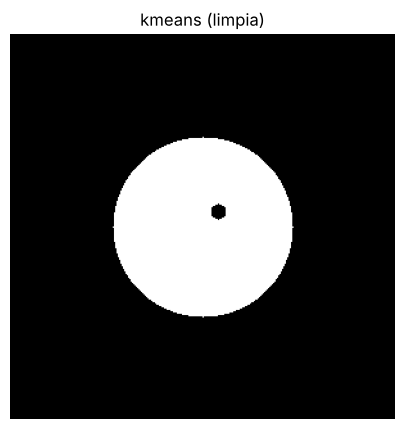

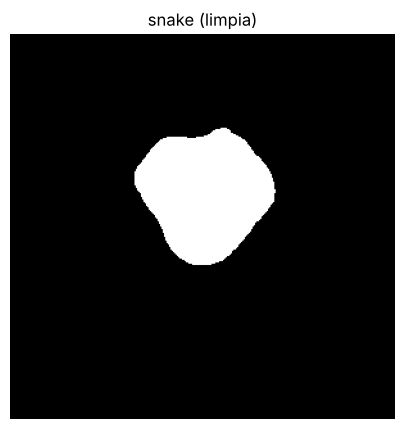

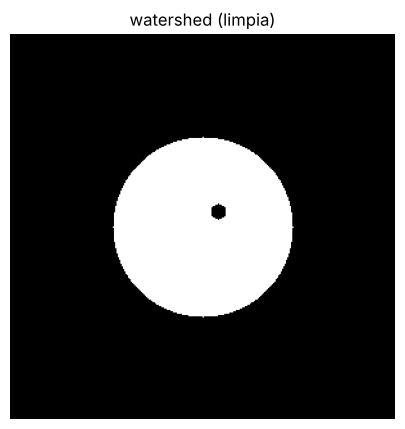

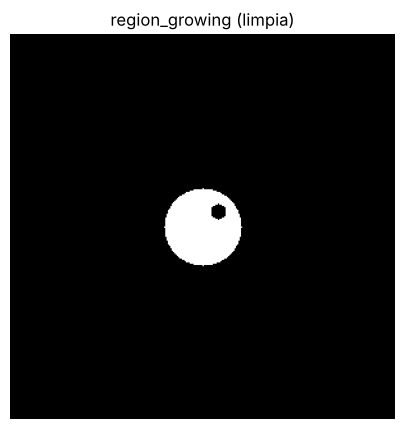

In [9]:
resultados_limpios = {}
for nombre, mascara in mascaras.items():
    limpia = morf.limpiar_mascara(mascara, tam_apertura=3, tam_cierre=5)
    limpia = morf.mayor_componente(limpia)
    resultados_limpios[nombre] = limpia
    mostrar(limpia, f"{nombre} (limpia)")

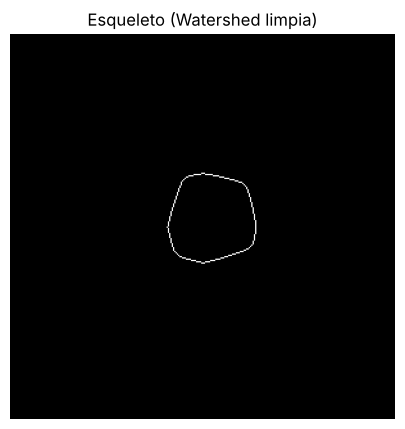

In [10]:
esqueleto = morf.esqueletizar(resultados_limpios["watershed"])
mostrar(esqueleto, "Esqueleto (Watershed limpia)")

**Descriptores morfométricos** (área, perímetro, centroide, circularidad, excentricidad):

In [11]:
for nombre, m in resultados_limpios.items():
    desc = morf.descriptores_morfometricos(m)
    print(nombre, desc)

otsu {'area_px': np.float64(15266.0), 'perimetro_px': np.float64(504.21529547664943), 'centroide_x': np.float64(149.91589152364733), 'centroide_y': np.float64(150.08410847635267), 'circularidad': np.float64(0.7546), 'excentricidad': 0.0406}
li {'area_px': np.float64(15266.0), 'perimetro_px': np.float64(504.21529547664943), 'centroide_x': np.float64(149.91589152364733), 'centroide_y': np.float64(150.08410847635267), 'circularidad': np.float64(0.7546), 'excentricidad': 0.0406}
triangle {'area_px': np.float64(37874.0), 'perimetro_px': np.float64(770.3229432149742), 'centroide_x': np.float64(149.96609811480172), 'centroide_y': np.float64(150.03390188519828), 'circularidad': np.float64(0.8021), 'excentricidad': 0.0164}
kmeans {'area_px': np.float64(15266.0), 'perimetro_px': np.float64(504.21529547664943), 'centroide_x': np.float64(149.91589152364733), 'centroide_y': np.float64(150.08410847635267), 'circularidad': np.float64(0.7546), 'excentricidad': 0.0406}
snake {'area_px': np.float64(8102

**Métricas Dice/IoU contra una referencia.** Con la imagen sintética ya está
`REFERENCIA`; con un video real, reemplazar por una máscara anotada a mano
(tal como pide la guía).

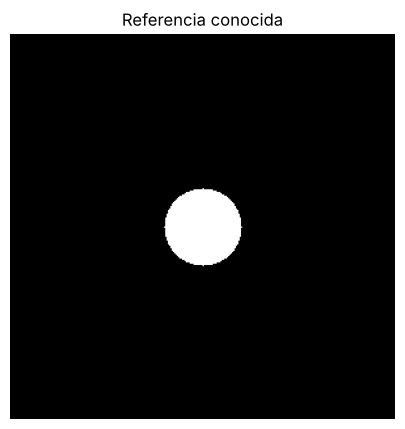

--- Máscara CRUDA vs. referencia ---
otsu             Dice=0.2995  IoU=0.1762
li               Dice=0.2995  IoU=0.1762
triangle         Dice=0.1331  IoU=0.0713
kmeans           Dice=0.2995  IoU=0.1762
snake            Dice=0.5151  IoU=0.3469
watershed        Dice=0.2995  IoU=0.1762
region_growing   Dice=0.9796  IoU=0.9599

--- Máscara LIMPIA vs. referencia ---
otsu             Dice=0.3001  IoU=0.1765
li               Dice=0.3001  IoU=0.1765
triangle         Dice=0.1334  IoU=0.0715
kmeans           Dice=0.3001  IoU=0.1765
snake            Dice=0.5151  IoU=0.3469
watershed        Dice=0.3001  IoU=0.1765
region_growing   Dice=0.9807  IoU=0.9621


In [12]:
if REFERENCIA is not None:
    mostrar(REFERENCIA, "Referencia conocida")
    print("--- Máscara CRUDA vs. referencia ---")
    for nombre, valores in morf.comparar_metodos(mascaras, REFERENCIA).items():
        print(f"{nombre:16s} Dice={valores['dice']:.4f}  IoU={valores['iou']:.4f}")
    print("\n--- Máscara LIMPIA vs. referencia ---")
    for nombre, valores in morf.comparar_metodos(resultados_limpios, REFERENCIA).items():
        print(f"{nombre:16s} Dice={valores['dice']:.4f}  IoU={valores['iou']:.4f}")
else:
    print("Cargar una máscara anotada a mano en REFERENCIA para video real.")

**Nota pedagógica:** si varios métodos dan resultados parecidos es porque
agrupan iris+pupila juntos (ambos oscuros frente al fondo) — tal como dice la
clase, "Otsu no detecta objetos, separa dos grupos de intensidades". Watershed
y Region Growing suelen aislar mejor la pupila sola porque parten de
marcadores/semillas puntuales.